<div style="padding:30px;border-radius:18px;background:linear-gradient(125deg,#071426,#12304a,#087e8b);color:#fff;border:1px solid #38bdf8">
<h1>Helmet Detection with YOLO</h1><h3 style="color:#a5f3fc">Dataset Exploration · Annotation Audit · Object Detection</h3>
<p><b>Dataset:</b> Helmet Detection Dataset (YOLO Format)<br><b>Author:</b> Mobeen Fatima · @mobeenfatimah</p></div>

### Dataset structure
The published dataset card describes **1,529 total files** across training and validation splits, with `train/images`, `train/labels`, `val/images`, `val/labels`, and `data.yaml`.

### Objectives
- Inspect dataset structure and configuration.
- Audit image/label pairs and YOLO annotation quality.
- Explore class balance and bounding-box geometry.
- Visualize ground-truth annotations.
- Provide optional Ultralytics YOLO training, validation, and inference.

> Class names and class count are read from `data.yaml`; they are not assumed. Training is disabled by default to avoid unexpectedly using compute.


## 1. Import libraries

Load lightweight tools for data handling, image processing, and visualization.

In [1]:
import os, glob, random, warnings
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display
print("Libraries ready.")

Libraries ready.


## 2. Reproducibility

Fix random seeds and configure Pandas display.

In [2]:
SEED=42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns",60)
pd.set_option("display.max_colwidth",100)
print("Seed:",SEED)

Seed: 42


## 3. Visualization theme

Set a consistent professional palette and readable plotting defaults.

In [3]:
plt.rcParams.update({"figure.figsize":(10,5.5),"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.2,"axes.titleweight":"bold"})
NAVY,CYAN,TEAL="#12304A","#38BDF8","#0F9D9A"
ORANGE,RED,GREEN="#F59E0B","#E76F51","#2A9D8F"
print("Style configured.")

Style configured.


## 4. Find data.yaml

Search Kaggle input and working directories for the dataset YAML file.

In [4]:
roots=["/kaggle/input",".","/kaggle/working"]
yamls=[]
for root in roots:
    if os.path.isdir(root): yamls += glob.glob(root+"/**/data.yaml",recursive=True)
yamls=sorted(set(yamls))
print("YAML files:",len(yamls))
for p in yamls[:20]: print(p)

YAML files: 1
/kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset/data.yaml


## 5. Select dataset root

Choose the helmet dataset YAML when possible, then identify its root directory.

In [5]:
preferred=[p for p in yamls if "helmet" in p.lower() and (Path(p).parent/"train").exists()]
fallback=[p for p in yamls if (Path(p).parent/"train").exists()]
if preferred: DATA_YAML=Path(preferred[0])
elif fallback: DATA_YAML=Path(fallback[0])
else: raise FileNotFoundError("Attach the Helmet Detection Dataset; no matching data.yaml found.")
ROOT=DATA_YAML.parent
print("YAML:",DATA_YAML,"\nRoot:",ROOT)

YAML: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset/data.yaml 
Root: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset


## 6. Inspect directory structure

List the immediate contents of the dataset root.

In [6]:
for p in sorted(ROOT.iterdir()):
    print(("DIR " if p.is_dir() else "FILE"),p.name)

FILE data.yaml
DIR  train
DIR  val


## 7. Read YAML configuration

Load the actual dataset configuration.

In [7]:
try:
    import yaml
except ImportError:
    %pip -q install pyyaml
    import yaml
with open(DATA_YAML,encoding="utf-8") as f: cfg=yaml.safe_load(f)
display(cfg)

{'path': 'C:/Users/User/Desktop/helmet_detection_project/dataset',
 'train': 'train/images',
 'val': 'val/images',
 'nc': 2,
 'names': ['Without helmet', 'With helmet']}

## 8. Extract class metadata

Support both list-based and dictionary-based YOLO class-name formats.

In [8]:
raw=cfg.get("names",[])
if isinstance(raw,dict): CLASS_NAMES=[str(raw[k]) for k in sorted(raw,key=lambda x:int(x))]
elif isinstance(raw,list): CLASS_NAMES=list(map(str,raw))
else: CLASS_NAMES=[]
NC=int(cfg.get("nc",len(CLASS_NAMES)))
print("nc =",NC,"\nclasses =",CLASS_NAMES)

nc = 2 
classes = ['Without helmet', 'With helmet']


## 9. Resolve split folders

Resolve train and validation paths from YAML or common directory conventions.

In [9]:
def split_path(key,options):
    v=cfg.get(key)
    cand=[(Path(v) if Path(v).is_absolute() else ROOT/str(v))] if v else []
    cand += [ROOT/x for x in options]
    return next((p for p in cand if p.exists()),cand[0] if cand else None)
TRAIN=split_path("train",["train/images","train"])
VAL=split_path("val",["val/images","valid/images","validation/images","val"])
print("Train:",TRAIN,"\nVal:",VAL)

Train: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset/train/images 
Val: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset/val/images


## 10. Resolve label folders

Find label directories paired with the image directories.

In [10]:
def labels_for(p,split):
    if p is None: return None
    if p.name=="images" and (p.parent/"labels").exists(): return p.parent/"labels"
    for x in [ROOT/split/"labels",ROOT/("valid" if split=="val" else split)/"labels"]:
        if x.exists(): return x
    return None
TRAIN_L=labels_for(TRAIN,"train"); VAL_L=labels_for(VAL,"val")
print("Train labels:",TRAIN_L,"\nVal labels:",VAL_L)

Train labels: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset/train/labels 
Val labels: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset/val/labels


## 11. Discover image files

Collect supported image formats recursively.

In [11]:
EXT={".jpg",".jpeg",".png",".bmp",".webp",".tif",".tiff"}
def images(p):
    return sorted(x for x in Path(p).rglob("*") if x.is_file() and x.suffix.lower() in EXT) if p and Path(p).exists() else []
train_imgs=images(TRAIN); val_imgs=images(VAL)
print("Train images:",len(train_imgs),"| Val images:",len(val_imgs))

Train images: 611 | Val images: 153


## 12. Discover label files

Count annotation text files in each split.

In [12]:
def label_files(p):
    return sorted(Path(p).rglob("*.txt")) if p and Path(p).exists() else []
train_txt=label_files(TRAIN_L); val_txt=label_files(VAL_L)
print("Train labels:",len(train_txt),"| Val labels:",len(val_txt))

Train labels: 611 | Val labels: 153


## 13. Match images and labels

Match each image with a same-stem text annotation file.

In [13]:
def match_label(img,folder):
    p=Path(folder)/ (Path(img).stem+".txt") if folder else None
    return p if p and p.exists() else None
train_pairs=[(p,match_label(p,TRAIN_L)) for p in train_imgs]
val_pairs=[(p,match_label(p,VAL_L)) for p in val_imgs]
print("Train matched:",sum(y is not None for x,y in train_pairs),"/",len(train_pairs))
print("Val matched:",sum(y is not None for x,y in val_pairs),"/",len(val_pairs))

Train matched: 611 / 611
Val matched: 153 / 153


## 14. Split summary

Create a compact train/validation count table.

In [14]:
summary=pd.DataFrame([["Train",len(train_imgs),len(train_txt),sum(y is not None for x,y in train_pairs)],["Validation",len(val_imgs),len(val_txt),sum(y is not None for x,y in val_pairs)]],columns=["split","images","label_files","matched_images"])
display(summary)

,split,images,label_files,matched_images
0,Train,611,611,611
1,Validation,153,153,153


## 15. Compare split sizes

Visualize image counts in both splits.

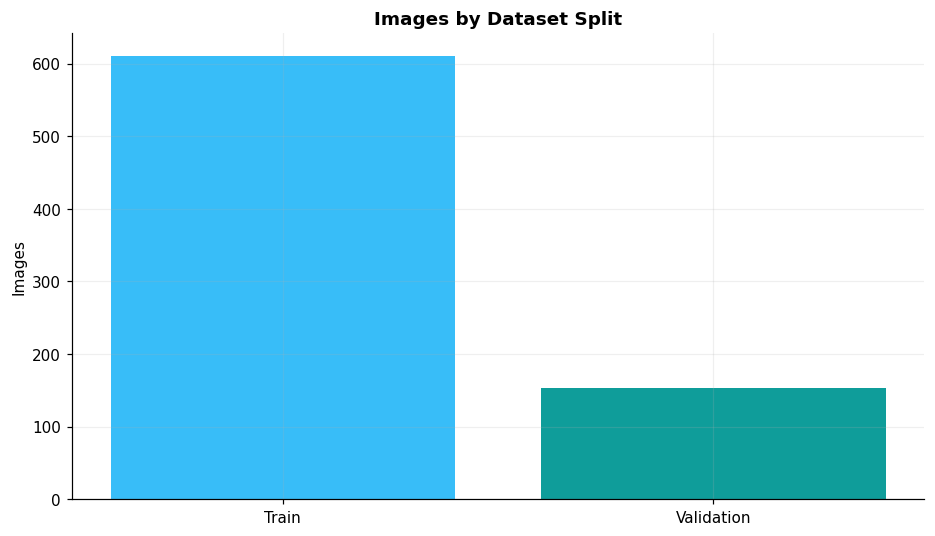

In [15]:
plt.bar(summary.split,summary.images,color=[CYAN,TEAL])
plt.title("Images by Dataset Split"); plt.ylabel("Images"); plt.show()

## 16. Image metadata

Read image width, height, and aspect ratio while handling corrupt files.

In [16]:
def metadata(paths):
    out=[]
    for p in paths:
        try:
            with Image.open(p) as im: w,h=im.size
            out.append([str(p),w,h,w/h])
        except Exception: out.append([str(p),np.nan,np.nan,np.nan])
    return pd.DataFrame(out,columns=["path","width","height","aspect_ratio"])
train_meta=metadata(train_imgs); val_meta=metadata(val_imgs)
display(train_meta[["width","height","aspect_ratio"]].describe().round(2))

,width,height,aspect_ratio
count,611.00,611.00,611.00
mean,404.86,298.74,1.42
std,71.34,74.87,0.33
min,150.00,138.00,0.56
25%,400.00,250.00,1.33
50%,400.00,268.00,1.50
75%,400.00,337.50,1.60
max,600.00,600.00,2.90


## 17. Resolution distributions

Plot training image widths and heights.

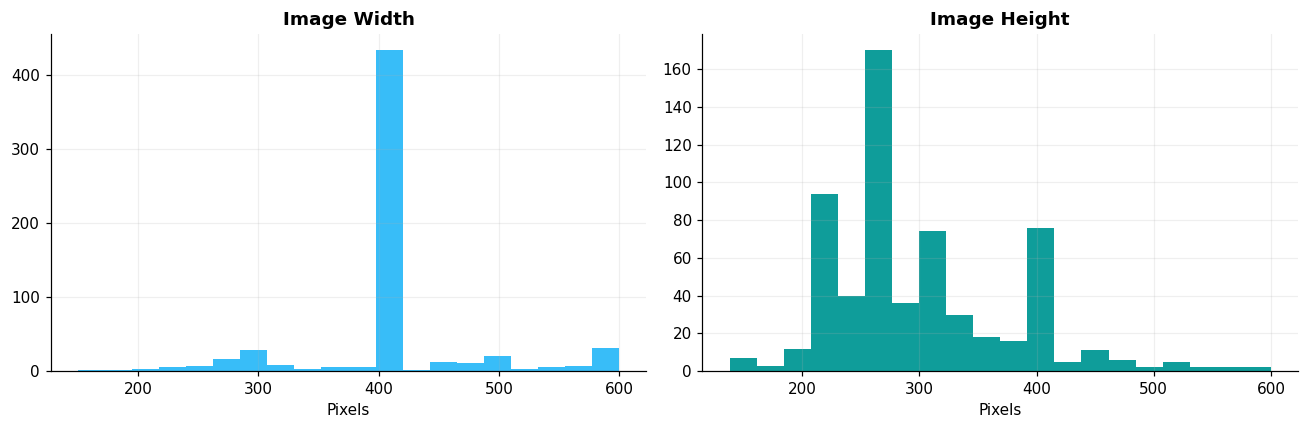

In [17]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(train_meta.width.dropna(),bins=20,color=CYAN); ax[0].set(title="Image Width",xlabel="Pixels")
ax[1].hist(train_meta.height.dropna(),bins=20,color=TEAL); ax[1].set(title="Image Height",xlabel="Pixels")
plt.tight_layout(); plt.show()

## 18. Aspect ratio analysis

Inspect image aspect ratios and the share of portrait, square, and landscape images.

Portrait: 61 Square: 31 Landscape: 519


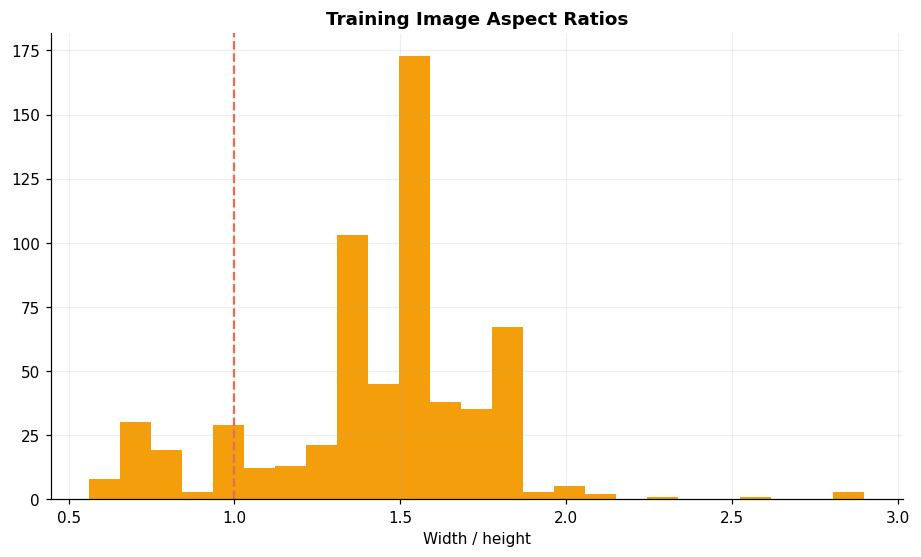

In [18]:
r=train_meta.aspect_ratio.dropna()
print("Portrait:",(r<.95).sum(),"Square:",((r>=.95)&(r<=1.05)).sum(),"Landscape:",(r>1.05).sum())
plt.hist(r,bins=25,color=ORANGE); plt.axvline(1,color=RED,ls="--")
plt.title("Training Image Aspect Ratios"); plt.xlabel("Width / height"); plt.show()

## 19. YOLO annotation parser

Define a parser for the five normalized values in each YOLO detection row.

In [19]:
def parse_label(path):
    rows=[]; errors=[]
    if path is None: return rows,errors
    for n,line in enumerate(Path(path).read_text(errors="ignore").splitlines(),1):
        if not line.strip(): continue
        a=line.split()
        if len(a)!=5: errors.append(f"line {n}: expected 5 values"); continue
        try:
            c,xc,yc,bw,bh=map(float,a)
            rows.append(dict(class_id=int(c),x_center=xc,y_center=yc,box_width=bw,box_height=bh))
        except Exception: errors.append(f"line {n}: invalid numeric values")
    return rows,errors
print("Parser ready.")

Parser ready.


## 20. Parse training labels

Build a table containing every valid training bounding box.

In [20]:
train_rows=[]; train_errors=[]
for img,lab in train_pairs:
    rec,err=parse_label(lab); train_errors.extend([(str(lab),e) for e in err])
    for x in rec: x["image"]=str(img); train_rows.append(x)
train_ann=pd.DataFrame(train_rows)
print("Boxes:",len(train_ann),"Malformed rows:",len(train_errors))
display(train_ann.head())

Boxes: 1153 Malformed rows: 0


,class_id,x_center,y_center,box_width,box_height,image
0,1,0.13875,0.496255,0.1325,0.205993,/kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection datas...
1,1,0.39375,0.411985,0.1775,0.329588,/kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection datas...
2,1,0.55875,0.264045,0.1125,0.205993,/kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection datas...
3,1,0.84750,0.232210,0.1600,0.337079,/kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection datas...
4,1,0.51625,0.136667,0.2275,0.273333,/kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection datas...


## 21. Parse validation labels

Build a corresponding table for validation bounding boxes.

In [21]:
val_rows=[]; val_errors=[]
for img,lab in val_pairs:
    rec,err=parse_label(lab); val_errors.extend([(str(lab),e) for e in err])
    for x in rec: x["image"]=str(img); val_rows.append(x)
val_ann=pd.DataFrame(val_rows)
print("Validation boxes:",len(val_ann),"Malformed rows:",len(val_errors))

Validation boxes: 298 Malformed rows: 0


## 22. Annotation statistics

Review the numeric distribution of normalized YOLO coordinates.

In [22]:
if len(train_ann):
    display(train_ann[["x_center","y_center","box_width","box_height"]].describe().round(4))
else: print("No valid training annotations found.")

,x_center,y_center,box_width,box_height
count,1153.0000,1153.0000,1153.0000,1153.0000
mean,5.2135,1.3905,1.0662,1.1832
std,49.7637,13.6234,9.2903,9.8957
min,0.0438,0.0554,0.0225,0.0309
25%,0.3748,0.1588,0.0650,0.1157
50%,0.5075,0.2303,0.0950,0.1529
75%,0.6500,0.3167,0.1333,0.1960
max,863.0000,297.5000,132.1650,151.0000


## 23. Validate class IDs

Check whether observed class IDs fit the configured number of classes.

In [23]:
if len(train_ann):
    bad=(train_ann.class_id<0)|(train_ann.class_id>=max(NC,1))
    print("Out-of-range class IDs:",int(bad.sum()))
    print("Observed IDs:",sorted(train_ann.class_id.unique()))

Out-of-range class IDs: 0
Observed IDs: [np.int64(0), np.int64(1)]


## 24. Validate normalized coordinates

Check values outside [0,1] and non-positive bounding-box dimensions.

In [24]:
if len(train_ann):
    cols=["x_center","y_center","box_width","box_height"]
    outside=((train_ann[cols]<0)|(train_ann[cols]>1)).any(axis=1)
    nonpositive=(train_ann[["box_width","box_height"]]<=0).any(axis=1)
    print("Outside normalized range:",int(outside.sum()))
    print("Non-positive dimensions:",int(nonpositive.sum()))

Outside normalized range: 13
Non-positive dimensions: 0


## 25. Class distribution

Count bounding boxes per class using labels from data.yaml.

In [25]:
class_counts=train_ann.class_id.value_counts().sort_index() if len(train_ann) else pd.Series(dtype=int)
class_counts.index=[CLASS_NAMES[i] if i<len(CLASS_NAMES) else f"class_{i}" for i in class_counts.index]
display(class_counts.rename("boxes").to_frame())

,boxes
Without helmet,386
With helmet,767


## 26. Plot class distribution

Visualize the class balance in training annotations.

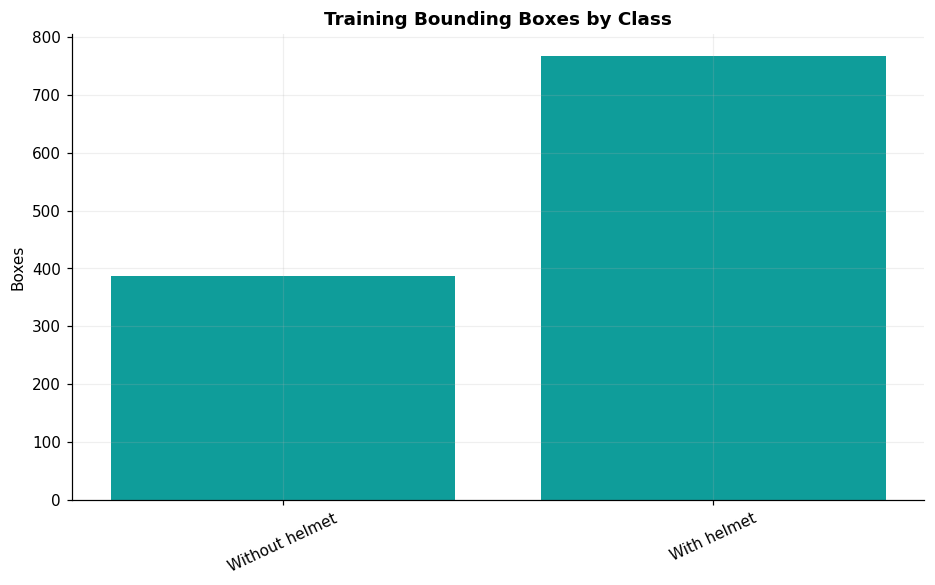

In [26]:
if len(class_counts):
    plt.bar(class_counts.index.astype(str),class_counts.values,color=TEAL)
    plt.title("Training Bounding Boxes by Class"); plt.ylabel("Boxes")
    plt.xticks(rotation=25); plt.show()

## 27. Objects per image

Count annotated objects per training image, including images without parsed boxes.

In [27]:
counts=train_ann.groupby("image").size() if len(train_ann) else pd.Series(dtype=int)
obj_per_img=pd.Series([counts.get(str(p),0) for p in train_imgs],index=[str(p) for p in train_imgs])
display(obj_per_img.describe().to_frame("objects_per_image"))

,objects_per_image
count,611.000000
mean,1.887070
std,1.412594
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,10.000000


## 28. Plot objects per image

Visualize the number of annotated objects in each image.

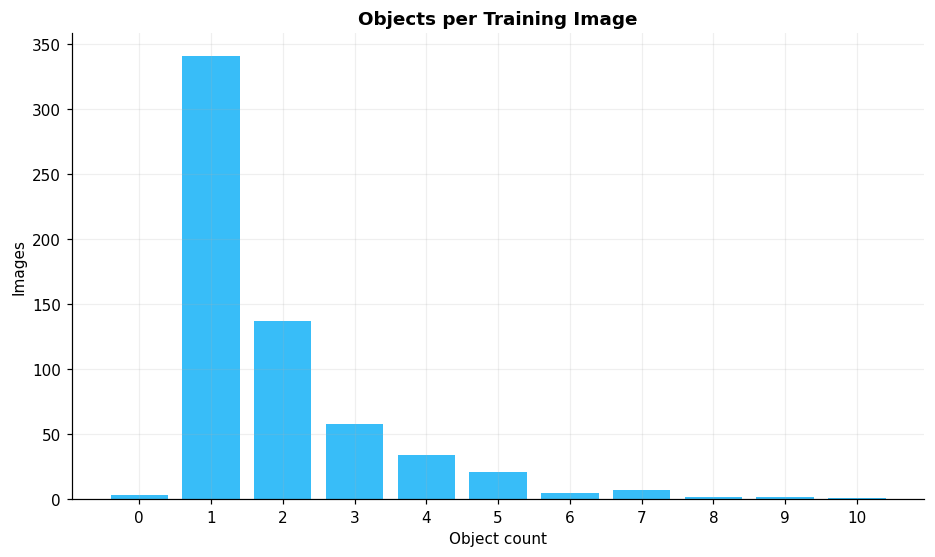

In [28]:
if len(obj_per_img):
    vc=obj_per_img.value_counts().sort_index()
    plt.bar(vc.index.astype(str),vc.values,color=CYAN)
    plt.title("Objects per Training Image"); plt.xlabel("Object count"); plt.ylabel("Images"); plt.show()

## 29. Box width and height

Inspect normalized bounding-box dimensions.

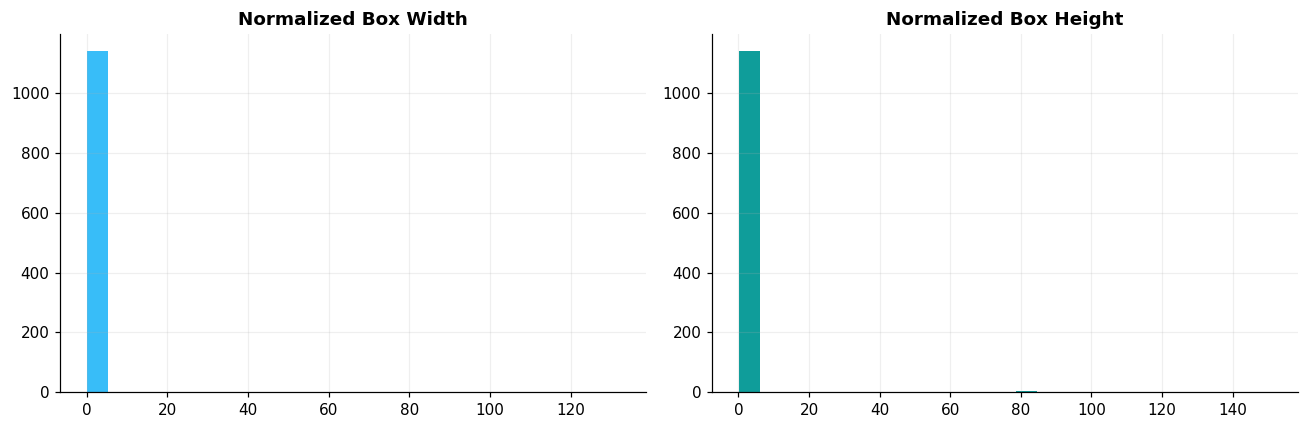

In [29]:
if len(train_ann):
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    ax[0].hist(train_ann.box_width,bins=25,color=CYAN); ax[0].set(title="Normalized Box Width")
    ax[1].hist(train_ann.box_height,bins=25,color=TEAL); ax[1].set(title="Normalized Box Height")
    plt.tight_layout(); plt.show()

## 30. Bounding-box area

Calculate normalized box area and inspect its distribution.

,normalized_area
count,1153.0000
mean,92.5462
std,984.0300
min,0.0009
25%,0.0075
50%,0.0146
75%,0.0257
max,19956.9150


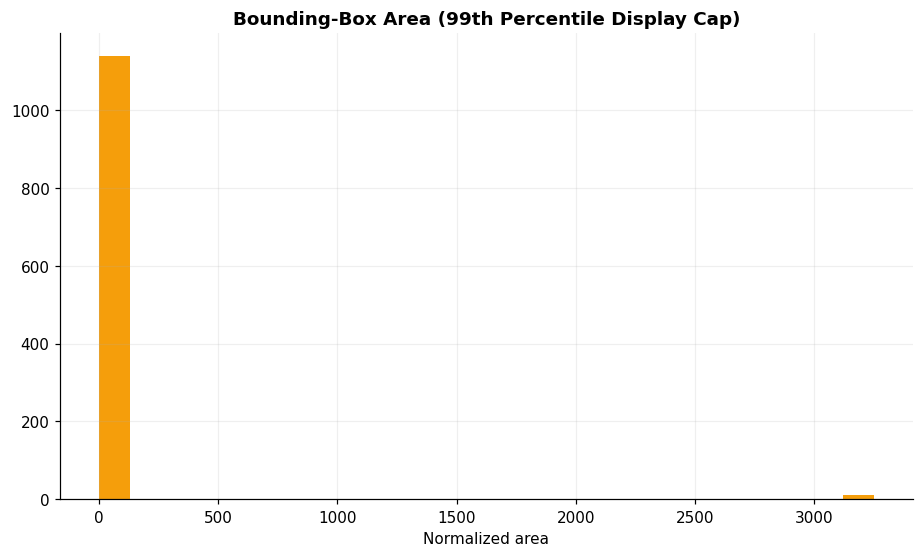

In [30]:
if len(train_ann):
    train_ann["box_area"]=train_ann.box_width*train_ann.box_height
    display(train_ann.box_area.describe().to_frame("normalized_area").round(4))
    plt.hist(train_ann.box_area.clip(upper=train_ann.box_area.quantile(.99)),bins=25,color=ORANGE)
    plt.title("Bounding-Box Area (99th Percentile Display Cap)"); plt.xlabel("Normalized area"); plt.show()

## 31. Bounding-box center map

Plot object centers to explore where objects occur in the image frame.

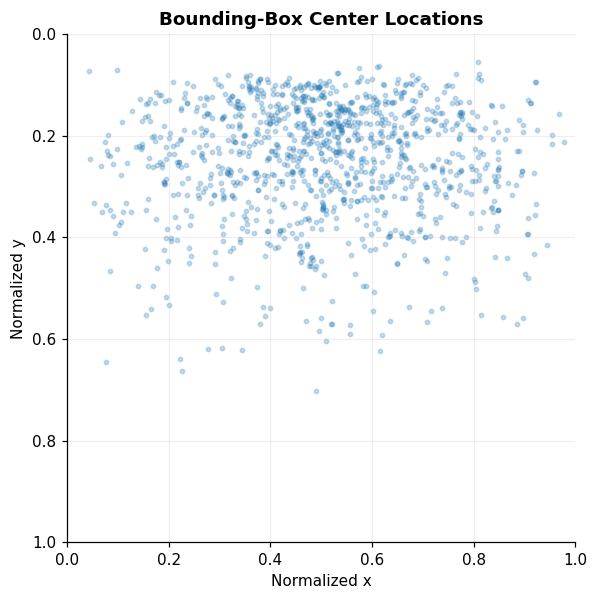

In [31]:
if len(train_ann):
    plt.figure(figsize=(7,6))
    plt.scatter(train_ann.x_center,train_ann.y_center,s=8,alpha=.25)
    plt.xlim(0,1); plt.ylim(1,0); plt.gca().set_aspect("equal")
    plt.title("Bounding-Box Center Locations"); plt.xlabel("Normalized x"); plt.ylabel("Normalized y"); plt.show()

## 32. Draw ground-truth boxes

Create a reusable function to render YOLO boxes on an image.

In [32]:
def draw_boxes(img_path,label_path,ax=None):
    im=Image.open(img_path).convert("RGB"); w,h=im.size; draw=ImageDraw.Draw(im)
    rec,_=parse_label(label_path)
    for r in rec:
        x1=(r["x_center"]-r["box_width"]/2)*w; y1=(r["y_center"]-r["box_height"]/2)*h
        x2=(r["x_center"]+r["box_width"]/2)*w; y2=(r["y_center"]+r["box_height"]/2)*h
        draw.rectangle([x1,y1,x2,y2],outline=(0,255,180),width=3)
        name=CLASS_NAMES[r["class_id"]] if r["class_id"]<len(CLASS_NAMES) else str(r["class_id"])
        draw.text((x1,max(0,y1-14)),name,fill=(255,255,0))
    if ax is None: plt.figure(figsize=(9,6)); plt.imshow(im); plt.axis("off"); plt.show()
    else: ax.imshow(im); ax.axis("off")
    return im
print("Visualization function ready.")

Visualization function ready.


## 33. Random training samples

Display up to six training images with their ground-truth boxes.

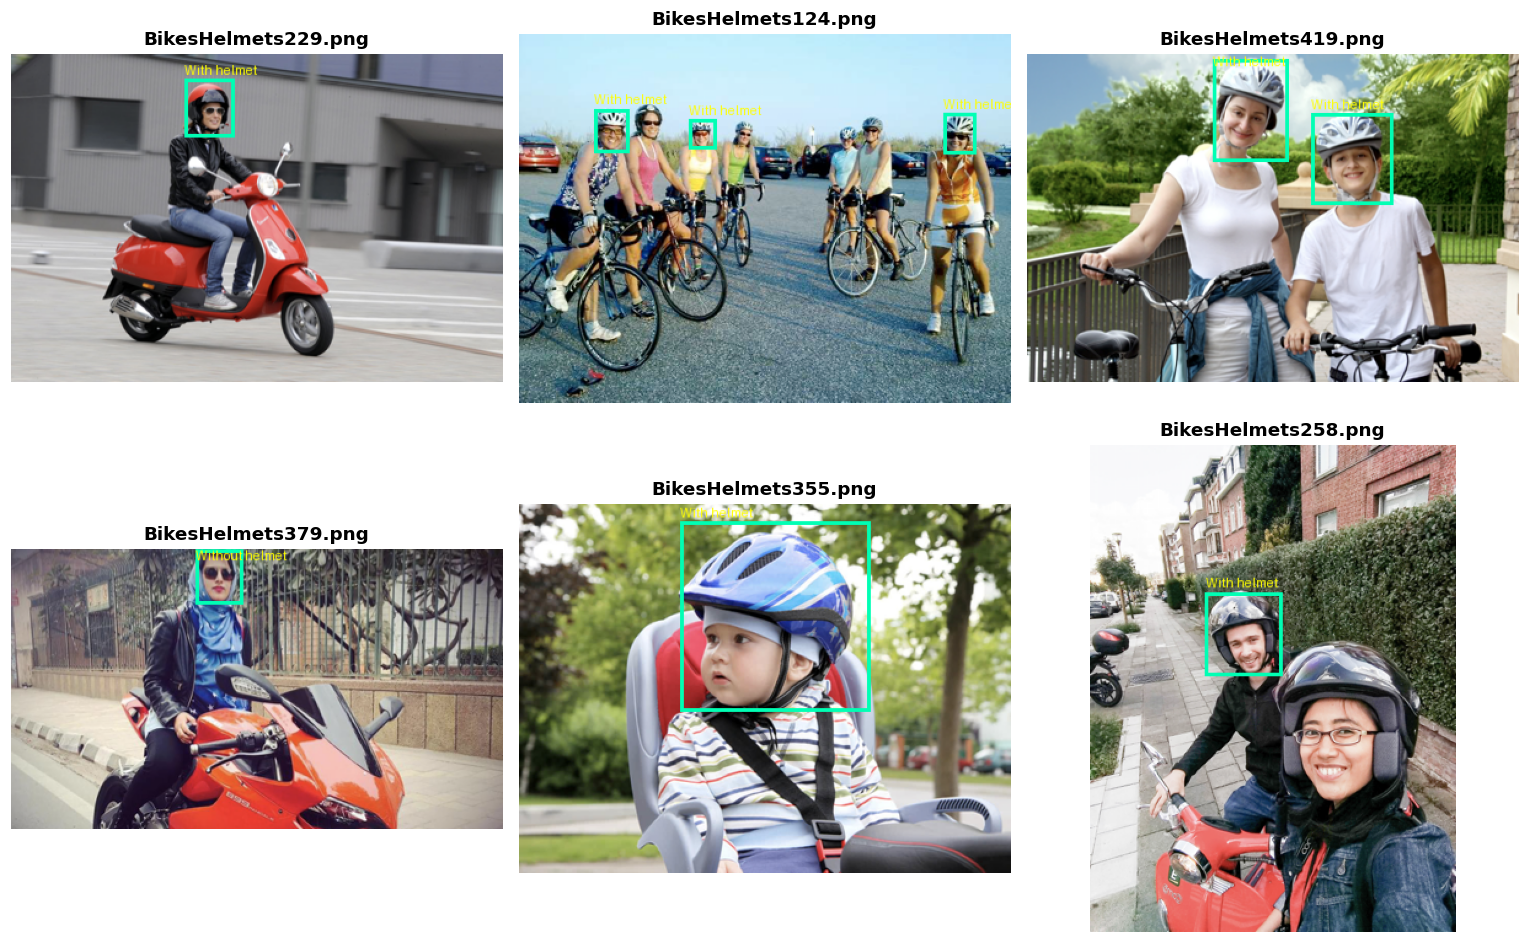

In [33]:
if train_pairs:
    sample=random.sample(train_pairs,min(6,len(train_pairs)))
    fig,ax=plt.subplots(2,3,figsize=(14,9))
    for a,(im,lab) in zip(ax.flat,sample):
        draw_boxes(im,lab,a); a.set_title(Path(im).name[:25])
    for a in ax.flat[len(sample):]: a.axis("off")
    plt.tight_layout(); plt.show()

## 34. Validation samples

Inspect a few validation images and their annotations.

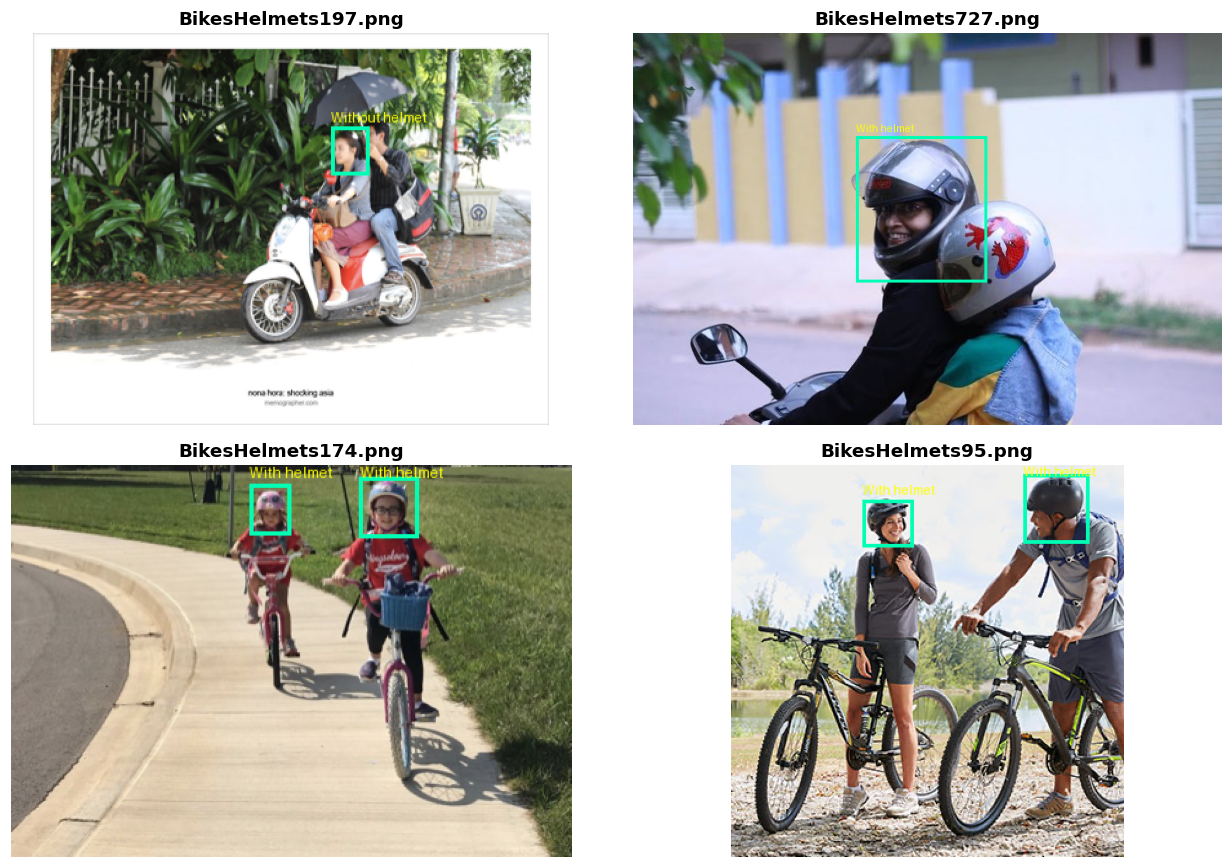

In [34]:
if val_pairs:
    sample=random.sample(val_pairs,min(4,len(val_pairs)))
    fig,ax=plt.subplots(2,2,figsize=(12,8))
    for a,(im,lab) in zip(ax.flat,sample):
        draw_boxes(im,lab,a); a.set_title(Path(im).name[:25])
    for a in ax.flat[len(sample):]: a.axis("off")
    plt.tight_layout(); plt.show()

## 35. Check image readability

Verify image files can be decoded without errors.

In [35]:
def unreadable(paths):
    bad=[]
    for p in paths:
        try:
            with Image.open(p) as im: im.verify()
        except Exception as e: bad.append((str(p),str(e)[:100]))
    return bad
bad_train=unreadable(train_imgs); bad_val=unreadable(val_imgs)
print("Unreadable train:",len(bad_train),"| Unreadable val:",len(bad_val))

Unreadable train: 0 | Unreadable val: 0


## 36. Missing and empty labels

Separate missing annotation files from existing but empty text files.

In [36]:
def audit_pairs(pairs):
    missing=[]; empty=[]
    for im,lab in pairs:
        if lab is None: missing.append(str(im))
        elif Path(lab).stat().st_size==0: empty.append(str(lab))
    return missing,empty
miss_tr,empty_tr=audit_pairs(train_pairs); miss_va,empty_va=audit_pairs(val_pairs)
display(pd.DataFrame([["Train",len(miss_tr),len(empty_tr)],["Val",len(miss_va),len(empty_va)]],
 columns=["split","missing_label_files","empty_label_files"]))

,split,missing_label_files,empty_label_files
0,Train,0,3
1,Val,0,0


## 37. Annotation quality report

Summarize key dataset and annotation checks.

In [37]:
report={"train_images":len(train_imgs),"val_images":len(val_imgs),
"train_boxes":len(train_ann),"val_boxes":len(val_ann),
"malformed_train_rows":len(train_errors),"malformed_val_rows":len(val_errors),
"unreadable_images":len(bad_train)+len(bad_val),
"missing_label_files":len(miss_tr)+len(miss_va)}
display(pd.Series(report,name="count").to_frame())

,count
train_images,611
val_images,153
train_boxes,1153
val_boxes,298
malformed_train_rows,0
malformed_val_rows,0
unreadable_images,0
missing_label_files,0


## 38. Check Ultralytics

Check whether the Ultralytics package is available in the runtime.

In [38]:
try:
    import ultralytics
    from ultralytics import YOLO
    print("Ultralytics:",ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed. Training can be enabled after installing it.")

Ultralytics is not installed. Training can be enabled after installing it.


## 39. Optional installation

If needed, uncomment the install command. Internet access may be required.

In [39]:
# Uncomment only if Ultralytics is not installed:
get_ipython().run_line_magic('pip', '-q install ultralytics')

Note: you may need to restart the kernel to use updated packages.


## 40. Configure YOLO training

Set a lightweight nano-model baseline and conservative training parameters.

In [40]:
MODEL="yolo11n.pt"
EPOCHS=30
IMGSZ=640
BATCH=8
PROJECT="/kaggle/working/helmet_yolo_runs"
RUN_NAME="helmet_yolo11n"
RUN_TRAINING=False
print({"model":MODEL,"epochs":EPOCHS,"imgsz":IMGSZ,"batch":BATCH,"training_enabled":RUN_TRAINING})

{'model': 'yolo11n.pt', 'epochs': 30, 'imgsz': 640, 'batch': 8, 'training_enabled': False}


## 41. Train detector (optional)

Set RUN_TRAINING=True to train. Pretrained weights may need to be downloaded if not cached.

In [41]:
training_results=None
if RUN_TRAINING:
    from ultralytics import YOLO
    model=YOLO(MODEL)
    training_results=model.train(data=str(DATA_YAML),epochs=EPOCHS,imgsz=IMGSZ,batch=BATCH,
        project=PROJECT,name=RUN_NAME,seed=SEED,workers=2,patience=8,plots=True)
else:
    print("Training skipped by default. Set RUN_TRAINING=True to start.")

Training skipped by default. Set RUN_TRAINING=True to start.


## 42. Validate trained model (optional)

Run validation only if training was enabled and the best checkpoint exists.

In [42]:
if RUN_TRAINING and training_results is not None:
    best=Path(PROJECT)/RUN_NAME/"weights"/"best.pt"
    if best.exists():
        detector=YOLO(str(best))
        metrics=detector.val(data=str(DATA_YAML),imgsz=IMGSZ)
        print(metrics)
    else: print("Best checkpoint not found:",best)
else: print("No training run in this session; validation skipped.")

No training run in this session; validation skipped.


## 43. Sample inference (optional)

Visualize predictions on one validation image when a trained checkpoint is available.

In [43]:
if RUN_TRAINING and training_results is not None and val_imgs:
    best=Path(PROJECT)/RUN_NAME/"weights"/"best.pt"
    if best.exists():
        detector=YOLO(str(best))
        result=detector.predict(str(val_imgs[0]),imgsz=IMGSZ,conf=.25,verbose=False)[0]
        display(Image.fromarray(result.plot()[...,::-1]))
    else: print("No best checkpoint found.")
else: print("Inference skipped; train a model first.")

Inference skipped; train a model first.


## 44. Export analysis tables

Save parsed labels and image metadata to the Kaggle working directory.

In [44]:
OUT=Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
if len(train_ann): train_ann.to_csv(OUT/"helmet_train_annotations.csv",index=False)
if len(val_ann): val_ann.to_csv(OUT/"helmet_val_annotations.csv",index=False)
train_meta.to_csv(OUT/"helmet_train_image_metadata.csv",index=False)
print("Saved analysis files to:",OUT.resolve())

Saved analysis files to: /kaggle/working


## 45. Final report

Print a compact summary of dataset contents and audit results.

In [45]:
print("="*55)
print("HELMET DETECTION — NOTEBOOK COMPLETE")
print("="*55)
print("Dataset:",ROOT)
print("Classes:",CLASS_NAMES)
print("Train:",len(train_imgs),"images,",len(train_ann),"boxes")
print("Validation:",len(val_imgs),"images,",len(val_ann),"boxes")
print("Malformed rows:",len(train_errors)+len(val_errors))
print("Unreadable images:",len(bad_train)+len(bad_val))
print("Training enabled:",RUN_TRAINING)
print("="*55)

HELMET DETECTION — NOTEBOOK COMPLETE
Dataset: /kaggle/input/datasets/mobeenfatimah/helmet-detection-dataset-yolo-format/helmet detection dataset
Classes: ['Without helmet', 'With helmet']
Train: 611 images, 1153 boxes
Validation: 153 images, 298 boxes
Malformed rows: 0
Unreadable images: 0
Training enabled: False


<div style="padding:26px;border-radius:18px;background:linear-gradient(125deg,#071426,#12304a,#087e8b);color:#fff;border:1px solid #38bdf8">
<h2 style="color:#a5f3fc">Conclusion</h2>
<p>This notebook explores the published Helmet Detection Dataset in YOLO format, audits its images and annotations, analyzes class and bounding-box distributions, and visualizes labeled examples.</p>
<p>The optional YOLO11n workflow supports training, validation, and sample inference. It is disabled by default so dataset exploration can run without starting a lengthy training process.</p>
<hr style="border-color:#38bdf8">
<p><b>Dataset:</b> Helmet Detection Dataset (YOLO Format)<br><b>Format:</b> Ultralytics YOLO object detection<br><b>Created by:</b> Mobeen Fatima · @mobeenfatimah</p></div>